# Estimating spread and volatility from price ranges

$\beta_t$ averages the sum of two adjacent squared one-bar ranges, while $\gamma_t$ measures one range over the same two bars:

$$
\beta_t=\frac{1}{w}\sum_{i=t-w+1}^{t}
\left[
\log^2\!\left(\frac{H_i}{L_i}\right)
+\log^2\!\left(\frac{H_{i-1}}{L_{i-1}}\right)
\right],
\qquad
\gamma_t=\log^2\!\left(
\frac{\max(H_t,H_{t-1})}{\min(L_t,L_{t-1})}
\right).
$$

Here, $H_i$ and $L_i$ are the observed high and low in bar $i$; $w$ is the rolling averaging length. $\beta_t$ is the smoothed two-bar range sum; $\gamma_t$ is the squared two-bar combined range; $\log$ is the natural logarithm.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Image

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib

DATA_URL = "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip"
DATA_DIR = ROOT / "data" / "public" / "binance"
DATA_PATH = ensure_dataset(ROOT, "binance_btcusdt")
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
expected_data_hash = "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == expected_data_hash
public_columns = ["Open time", "Open", "High", "Low", "Close", "Volume", "Close time", "Quote volume", "Trades", "Buyer base volume", "Buyer quote volume", "Unused"]
raw = pd.read_csv(DATA_PATH, compression="zip", header=None, names=public_columns, nrows=None)
raw["time"] = pd.to_datetime(raw["Open time"], unit="ms", utc=True).dt.tz_convert(None)
raw = raw.rename(columns={"Close": "close", "Volume": "volume", "Quote volume": "quote_volume", "Trades": "trades"})
raw = raw.sort_values("time").drop_duplicates("time").reset_index(drop=True)

from RiskLabAI.features.microstructural_features import alpha_estimates, bekker_parkinson_volatility_estimates, beta_estimates, corwin_schultz_estimator, edge_estimator, gamma_estimates, sigma_estimates

numeric_columns = ["Open", "High", "Low", "close", "volume", "quote_volume", "trades"]
raw[numeric_columns] = raw[numeric_columns].apply(pd.to_numeric)
minute = raw.rename(columns={"Open": "open", "High": "high", "Low": "low"}).set_index("time")[["open", "high", "low", "close", "volume", "quote_volume", "trades"]]

def make_bars(rule):
    return minute.resample(rule).agg({"open": "first", "high": "max", "low": "min", "close": "last", "volume": "sum", "quote_volume": "sum", "trades": "sum"}).dropna()

bars_15 = make_bars("15min")

FIGURES = ROOT / "outputs" / "figures" / "11_market_microstructure"
TABLES = ROOT / "outputs" / "tables" / "11_market_microstructure"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Two Range Scales

,Component,Mean,Median,90th percentile,Zero share
0,Beta,0.000361,0.000270,0.000721,0
1,Gamma,0.000357,0.000181,0.000711,0
2,Alpha,0.010235,0.007868,0.025295,0.305903
3,"Spread, basis points",102.348649,78.683174,252.938884,0.305903


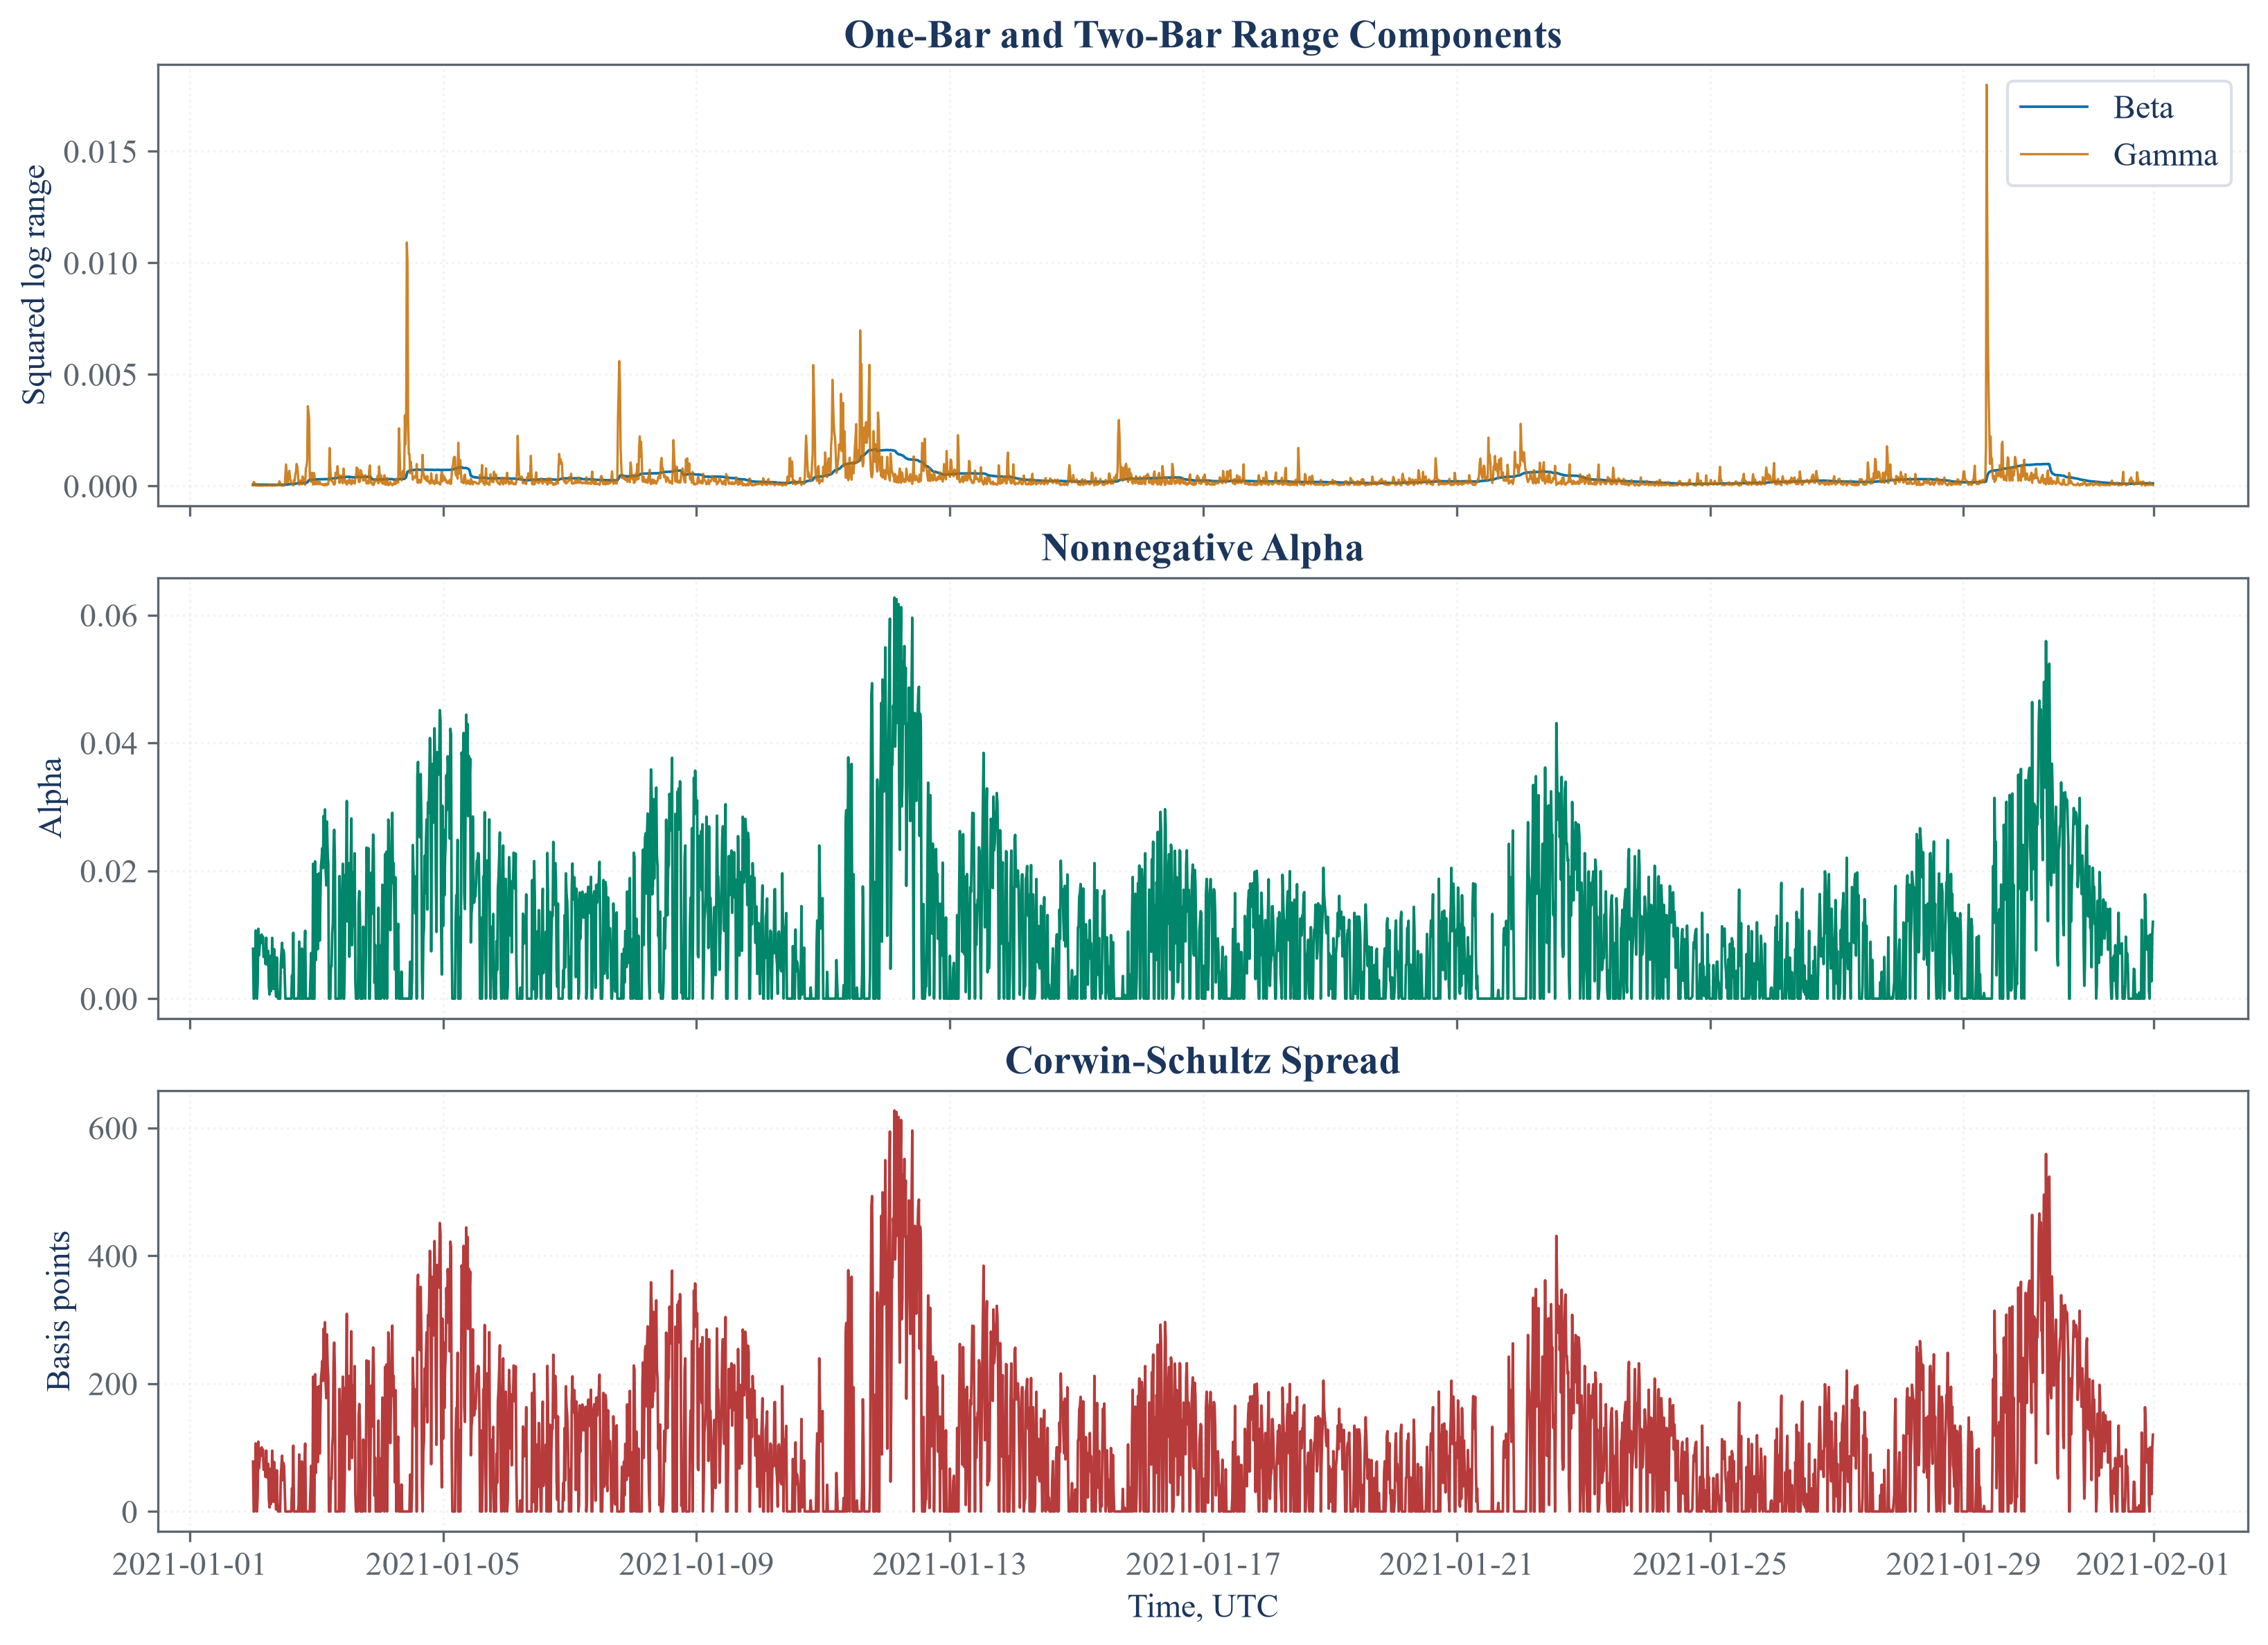

In [2]:
window_span = 96
public_high = bars_15["high"]
public_low = bars_15["low"]
beta = beta_estimates(public_high, public_low, window_span)
gamma = gamma_estimates(public_high, public_low)
alpha = alpha_estimates(beta, gamma)
spread = corwin_schultz_estimator(public_high, public_low, window_span)

component_frame = pd.concat([beta.rename("Beta"), gamma.rename("Gamma"), alpha.rename("Alpha"), spread.rename("Spread")], axis=1).dropna()
corwin_schultz_components = pd.DataFrame({
    "Component": ["Beta", "Gamma", "Alpha", "Spread, basis points"],
    "Mean": [component_frame["Beta"].mean(), component_frame["Gamma"].mean(), component_frame["Alpha"].mean(), 10000 * component_frame["Spread"].mean()],
    "Median": [component_frame["Beta"].median(), component_frame["Gamma"].median(), component_frame["Alpha"].median(), 10000 * component_frame["Spread"].median()],
    "90th percentile": [component_frame["Beta"].quantile(0.90), component_frame["Gamma"].quantile(0.90), component_frame["Alpha"].quantile(0.90), 10000 * component_frame["Spread"].quantile(0.90)],
    "Zero share": [(component_frame["Beta"] == 0).mean(), (component_frame["Gamma"] == 0).mean(), (component_frame["Alpha"] == 0).mean(), (component_frame["Spread"] == 0).mean()],
})
save_table(corwin_schultz_components, "corwin_schultz_components", "Public Corwin-Schultz component summaries for a 96-bar averaging length.", "tab:chapter10-corwin-schultz-components", fit=True)
display(corwin_schultz_components.round(8))

figure, axes = plt.subplots(3, 1, figsize=(10.8, 7.8), sharex=True, constrained_layout=True)
axes[0].plot(component_frame.index, component_frame["Beta"], color=palette["cyan"], linewidth=0.9, label="Beta")
axes[0].plot(component_frame.index, component_frame["Gamma"], color=palette["amber"], linewidth=0.8, alpha=0.85, label="Gamma")
axes[0].set_title("One-Bar and Two-Bar Range Components")
axes[0].set_ylabel("Squared log range")
axes[0].legend()
axes[1].plot(component_frame.index, component_frame["Alpha"], color=palette["green"], linewidth=0.9)
axes[1].set_title("Nonnegative Alpha")
axes[1].set_ylabel("Alpha")
axes[2].plot(component_frame.index, 10000 * component_frame["Spread"], color=palette["rose"], linewidth=0.9)
axes[2].set_title("Corwin-Schultz Spread")
axes[2].set_xlabel("Time, UTC")
axes[2].set_ylabel("Basis points")
for axis in axes:
    axis.grid(alpha=0.35)
figure.savefig(FIGURES / "corwin_schultz_components.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "corwin_schultz_components.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "corwin_schultz_components.png")))
plt.close(figure)

## Spread from Alpha

The estimator removes a two-bar movement term from the average one-bar ranges, then maps the nonnegative remainder to a proportional spread:

$$
d=3-2\sqrt{2},
\qquad
\alpha_t=\max\!\left\{0,
\frac{(\sqrt{2}-1)\sqrt{\beta_t}}{d}
-\sqrt{\frac{\gamma_t}{d}}
\right\},
\qquad
\widehat S_t=\frac{2(e^{\alpha_t}-1)}{1+e^{\alpha_t}}.
$$

Here, $d$ is a fixed constant; $\beta_t$ and $\gamma_t$ are the two range measurements defined above. $\alpha_t$ is the nonnegative intermediate value; $e$ is the exponential base; $\widehat S_t$ is the estimated proportional spread.

In [3]:
sensitivity_rows = []
for current_window in [12, 24, 48, 96, 192]:
    current_beta = beta_estimates(public_high, public_low, current_window)
    current_gamma = gamma_estimates(public_high, public_low)
    current_alpha = alpha_estimates(current_beta, current_gamma)
    current_spread = corwin_schultz_estimator(public_high, public_low, current_window)
    valid = pd.concat([current_beta.rename("Beta"), current_gamma.rename("Gamma"), current_alpha.rename("Alpha"), current_spread.rename("Spread")], axis=1).dropna()
    sensitivity_rows.append({"Averaging bars": current_window, "Available estimates": len(valid), "Median beta": valid["Beta"].median(), "Median gamma": valid["Gamma"].median(), "Median spread, basis points": 10000 * valid["Spread"].median(), "Mean spread, basis points": 10000 * valid["Spread"].mean(), "Zero spread share": (valid["Spread"] == 0).mean()})
estimator_window_sensitivity = pd.DataFrame(sensitivity_rows)
save_table(estimator_window_sensitivity, "estimator_window_sensitivity", "Corwin-Schultz estimates across five averaging lengths.", "tab:chapter10-estimator-window-sensitivity", fit=True)
display(estimator_window_sensitivity.round(8))

,Averaging bars,Available estimates,Median beta,Median gamma,"Median spread, basis points","Mean spread, basis points",Zero spread share
0,12,2964,0.000217,0.000175,44.094222,76.914141,0.352227
1,24,2952,0.000227,0.000176,54.288295,85.404947,0.333333
2,48,2928,0.000236,0.000177,66.215872,92.266774,0.323087
3,96,2880,0.000270,0.000181,78.683174,102.348649,0.305903
4,192,2784,0.000293,0.000183,94.773060,117.138586,0.286279


## Reconciling the published formula with the library

The checked published equation combines the one-bar and two-bar ranges to estimate volatility after separating the spread component:

$$
k_2=\sqrt{\frac{8}{\pi}},
\qquad
\widehat\sigma_{BP,t}
=\max\!\left\{0,
\frac{(2^{-1/2}-1)\sqrt{\beta_t}}{k_2d}
+\sqrt{\frac{\gamma_t}{k_2^2d}}
\right\}.
$$

Here, $k_2$ and $d=3-2\sqrt{2}$ are constants; $\beta_t$ and $\gamma_t$ are the range measurements. $\widehat\sigma_{BP,t}$ is the published Bekker-Parkinson volatility estimate; $\pi$ is the circle constant; the maximum floors negative values at zero.

This is the calculation in the current public RiskLabAI function, shown separately because its first term differs from the checked published equation:

$$
\widehat\sigma_{\mathrm{lib},t}
=\max\!\left\{0,
\frac{(\sqrt{2}-1)\sqrt{\beta_t}}{d}
+\sqrt{\frac{\gamma_t}{k_2^2d}}
\right\}.
$$

Here, $\widehat\sigma_{\mathrm{lib},t}$ is the current library output; $\beta_t,\gamma_t,k_2$ and $d$ have the definitions above. $\sqrt{2}-1$ is positive, whereas the published coefficient $2^{-1/2}-1$ is negative and is divided by $k_2.$

,Check,Published equation,Current library
0,First beta coefficient,(2^(-1/2)-1)/(k2 d),(sqrt(2)-1)/d
1,First beta term sign,Negative,Positive
2,Division by k2 in first term,Yes,No
3,First valid fixture value,0.014831,0.112169
4,Public median,0.002046,0.060890


,Quantity,10th percentile,Median,90th percentile,Mean
0,"Corwin-Schultz spread, basis points",0,78.683174,252.938884,102.348649
1,Published volatility,0,0.002046,0.019637,0.006887
2,Current library volatility,0.041949,0.060890,0.101877,0.067399
3,Library minus published volatility,0.038879,0.055043,0.089967,0.060512


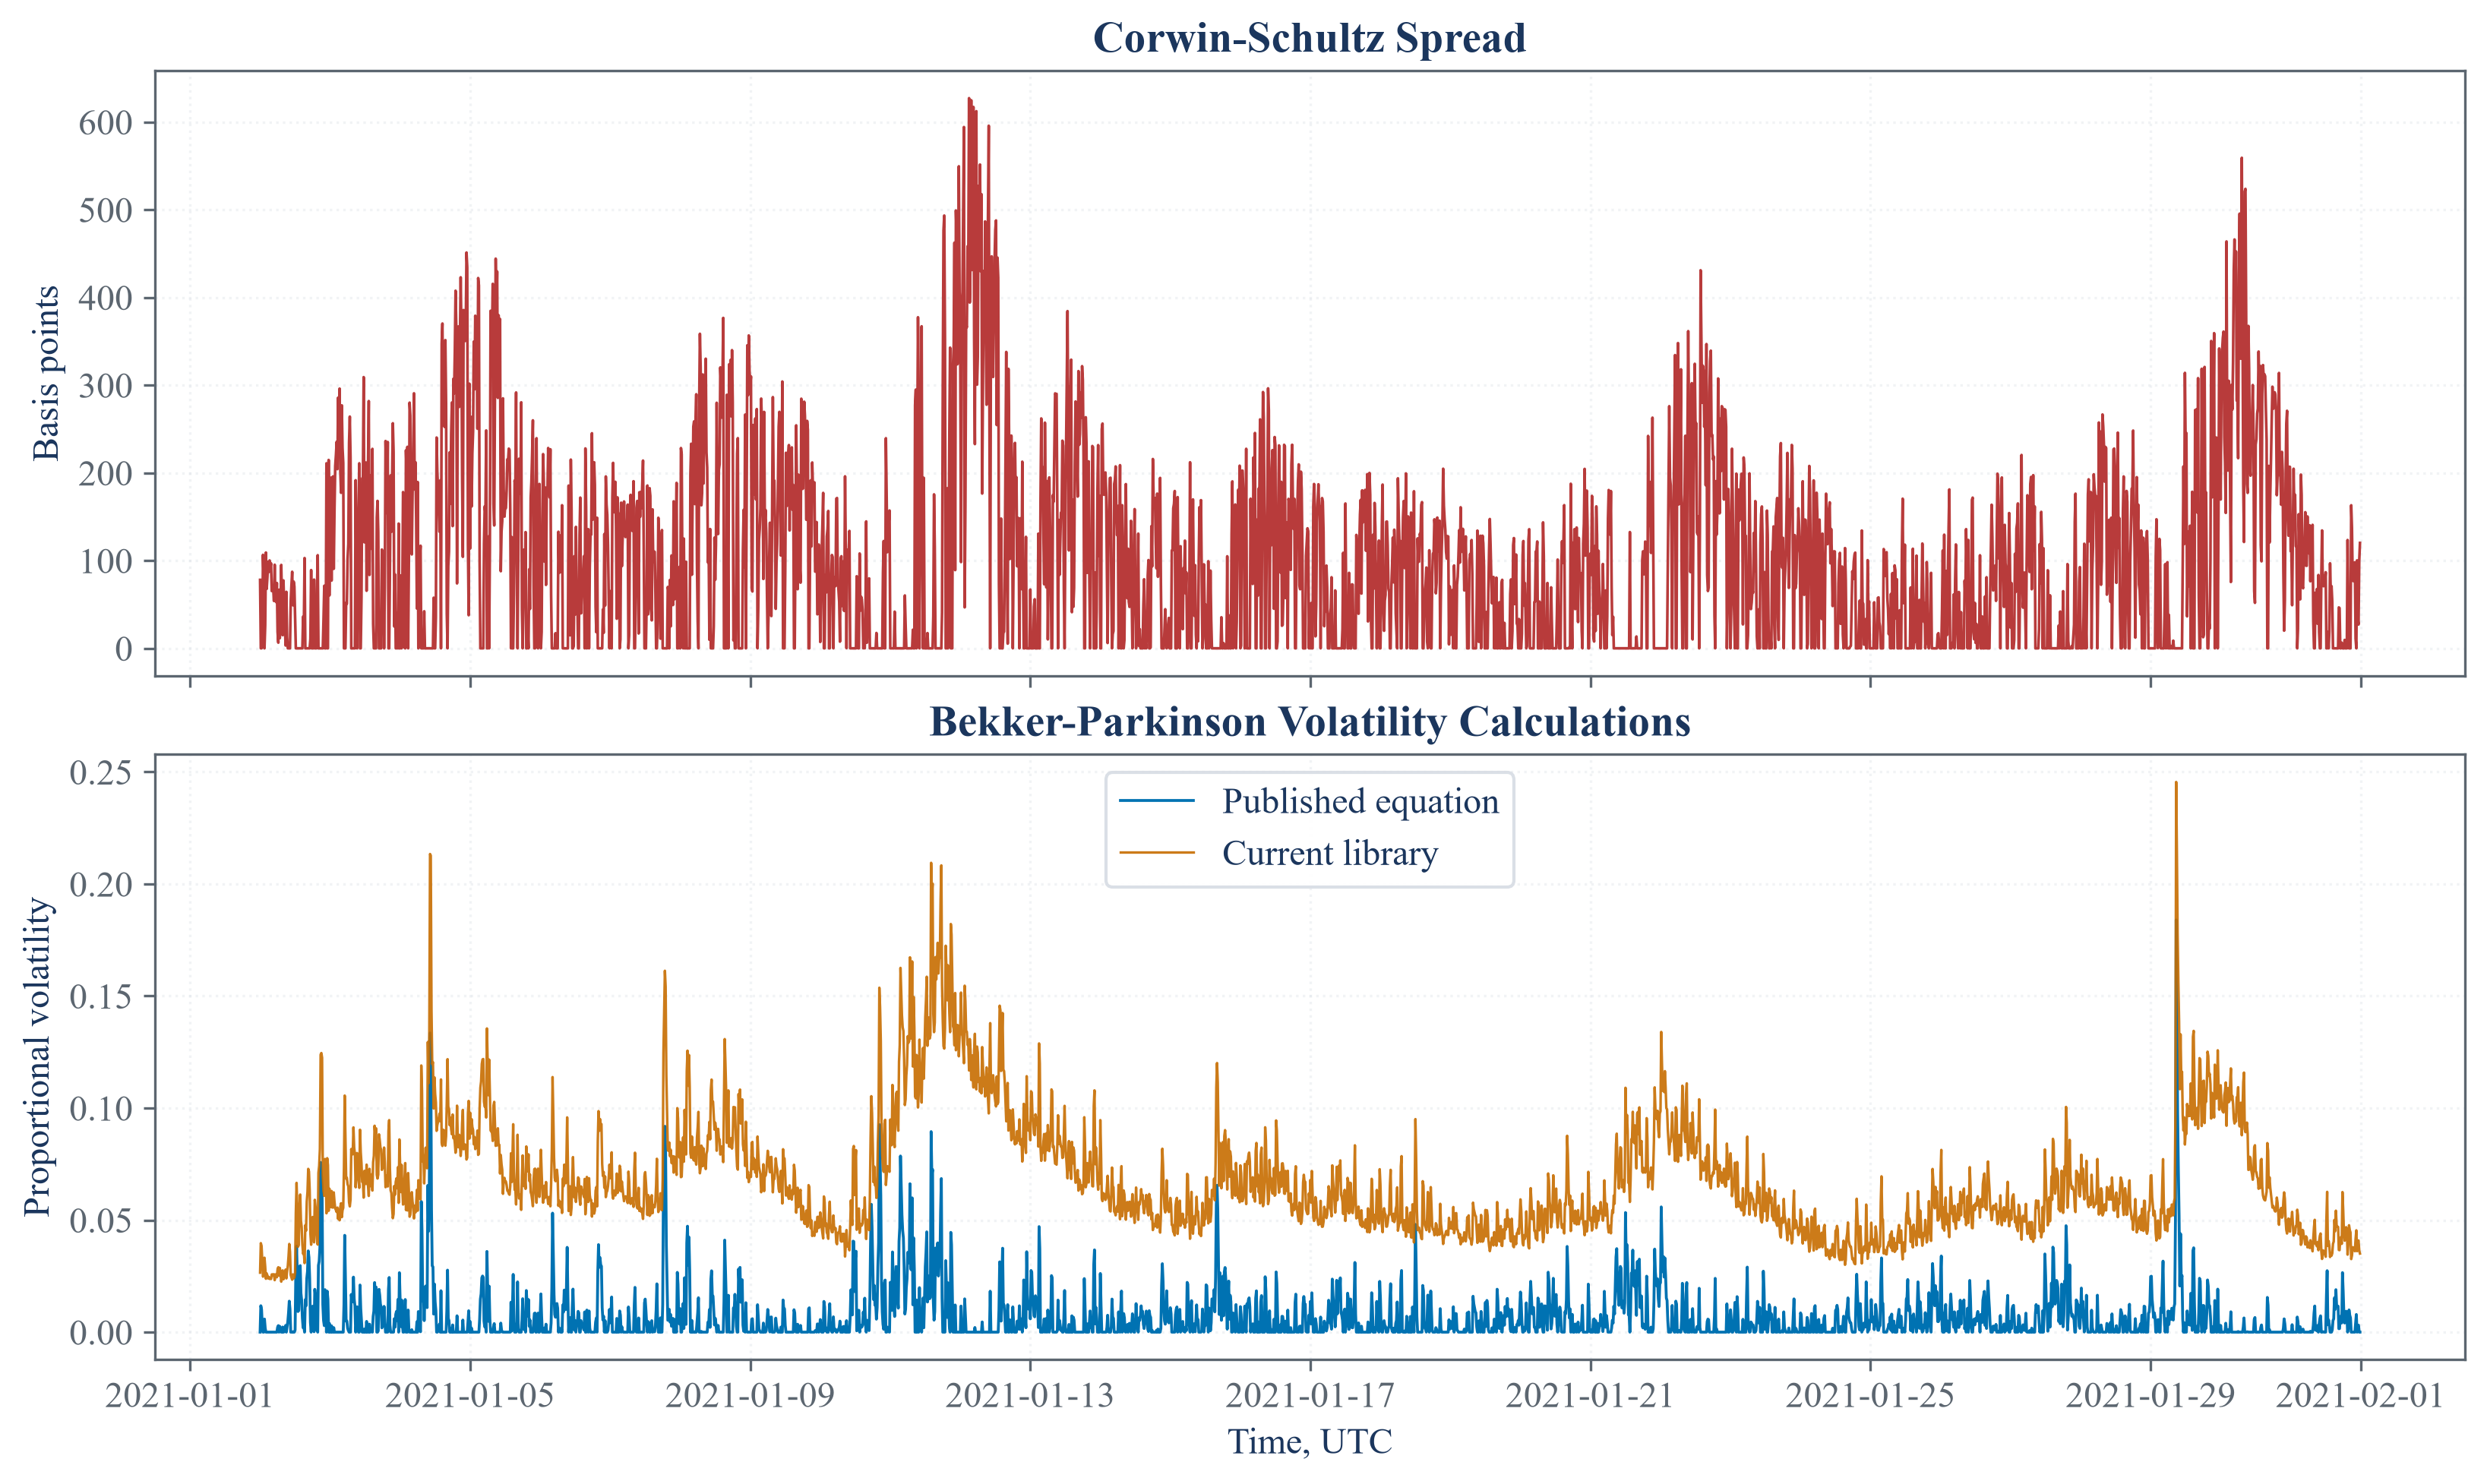

In [4]:
d_constant = 3 - 2 * np.sqrt(2)
k2_constant = np.sqrt(8 / np.pi)
published_volatility = np.maximum((2 ** -0.5 - 1) * np.sqrt(beta) / (k2_constant * d_constant) + np.sqrt(gamma / (k2_constant**2 * d_constant)), 0)
library_volatility = sigma_estimates(beta, gamma)
wrapper_volatility = bekker_parkinson_volatility_estimates(public_high, public_low, window_span)
volatility_frame = pd.concat([spread.rename("Spread"), pd.Series(published_volatility, index=beta.index, name="Published volatility"), library_volatility.rename("Library volatility")], axis=1).dropna()

fixture_high = pd.Series([10.1, 10.3, 10.2, 10.4, 10.5])
fixture_low = pd.Series([9.9, 10.1, 10.0, 10.2, 10.3])
fixture_beta = beta_estimates(fixture_high, fixture_low, 2)
fixture_gamma = gamma_estimates(fixture_high, fixture_low)
fixture_published = np.maximum((2 ** -0.5 - 1) * np.sqrt(fixture_beta) / (k2_constant * d_constant) + np.sqrt(fixture_gamma / (k2_constant**2 * d_constant)), 0)
fixture_library = sigma_estimates(fixture_beta, fixture_gamma)
first_valid = fixture_published.first_valid_index()

bekker_parkinson_formula_audit = pd.DataFrame({
    "Check": ["First beta coefficient", "First beta term sign", "Division by k2 in first term", "First valid fixture value", "Public median"],
    "Published equation": ["(2^(-1/2)-1)/(k2 d)", "Negative", "Yes", f"{fixture_published.loc[first_valid]:.6f}", f"{volatility_frame['Published volatility'].median():.6f}"],
    "Current library": ["(sqrt(2)-1)/d", "Positive", "No", f"{fixture_library.loc[first_valid]:.6f}", f"{volatility_frame['Library volatility'].median():.6f}"],
})
save_table(bekker_parkinson_formula_audit, "bekker_parkinson_formula_audit", "Checked published equation and current public library calculation.", "tab:chapter10-bekker-parkinson-formula-audit", fit=True)
display(bekker_parkinson_formula_audit)

spread_volatility_quantiles = pd.DataFrame({
    "Quantity": ["Corwin-Schultz spread, basis points", "Published volatility", "Current library volatility", "Library minus published volatility"],
    "10th percentile": [10000 * volatility_frame["Spread"].quantile(0.10), volatility_frame["Published volatility"].quantile(0.10), volatility_frame["Library volatility"].quantile(0.10), (volatility_frame["Library volatility"] - volatility_frame["Published volatility"]).quantile(0.10)],
    "Median": [10000 * volatility_frame["Spread"].median(), volatility_frame["Published volatility"].median(), volatility_frame["Library volatility"].median(), (volatility_frame["Library volatility"] - volatility_frame["Published volatility"]).median()],
    "90th percentile": [10000 * volatility_frame["Spread"].quantile(0.90), volatility_frame["Published volatility"].quantile(0.90), volatility_frame["Library volatility"].quantile(0.90), (volatility_frame["Library volatility"] - volatility_frame["Published volatility"]).quantile(0.90)],
    "Mean": [10000 * volatility_frame["Spread"].mean(), volatility_frame["Published volatility"].mean(), volatility_frame["Library volatility"].mean(), (volatility_frame["Library volatility"] - volatility_frame["Published volatility"]).mean()],
})
save_table(spread_volatility_quantiles, "spread_volatility_quantiles", "Public spread and volatility estimate distributions.", "tab:chapter10-spread-volatility-quantiles", fit=True)
display(spread_volatility_quantiles.round(6))

figure, axes = plt.subplots(2, 1, figsize=(10.8, 6.4), sharex=True, constrained_layout=True)
axes[0].plot(volatility_frame.index, 10000 * volatility_frame["Spread"], color=palette["rose"], linewidth=0.85)
axes[0].set_title("Corwin-Schultz Spread")
axes[0].set_ylabel("Basis points")
axes[1].plot(volatility_frame.index, volatility_frame["Published volatility"], color=palette["cyan"], linewidth=0.9, label="Published equation")
axes[1].plot(volatility_frame.index, volatility_frame["Library volatility"], color=palette["amber"], linewidth=0.8, alpha=0.9, label="Current library")
axes[1].set_title("Bekker-Parkinson Volatility Calculations")
axes[1].set_xlabel("Time, UTC")
axes[1].set_ylabel("Proportional volatility")
axes[1].legend()
for axis in axes:
    axis.grid(alpha=0.35)
figure.savefig(FIGURES / "spread_volatility_estimates.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "spread_volatility_estimates.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "spread_volatility_estimates.png")))
plt.close(figure)

## Tests

In [5]:
manual_log_range_squared = np.log(public_high / public_low) ** 2
manual_beta = manual_log_range_squared.rolling(2).sum().rolling(window_span).mean()
manual_gamma = np.log(public_high.rolling(2).max() / public_low.rolling(2).min()) ** 2
manual_alpha = np.maximum((np.sqrt(2) - 1) * np.sqrt(manual_beta) / d_constant - np.sqrt(manual_gamma / d_constant), 0)
manual_spread = 2 * (np.exp(manual_alpha) - 1) / (1 + np.exp(manual_alpha))
assert data_hash == "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
assert len(component_frame) == len(bars_15) - window_span
assert np.allclose(beta.dropna(), manual_beta.dropna())
assert np.allclose(gamma.dropna(), manual_gamma.dropna())
assert np.allclose(alpha.dropna(), manual_alpha.dropna())
assert np.allclose(spread.dropna(), manual_spread.dropna())
assert np.allclose(library_volatility.dropna(), wrapper_volatility.dropna())
assert (alpha.dropna() >= 0).all()
assert spread.dropna().between(0, 2).all()
assert estimator_window_sensitivity["Available estimates"].is_monotonic_decreasing
assert estimator_window_sensitivity["Zero spread share"].between(0, 1).all()
assert not np.allclose(fixture_published.dropna(), fixture_library.dropna())
assert not np.allclose(volatility_frame["Published volatility"], volatility_frame["Library volatility"])
assert np.isclose(fixture_published.loc[first_valid], 0.014830915437167, atol=1e-12)
assert np.isclose(fixture_library.loc[first_valid], 0.112169310280388, atol=1e-12)
assert (volatility_frame["Published volatility"] >= 0).all()
assert (volatility_frame["Library volatility"] >= 0).all()
assert (volatility_frame["Library volatility"] > volatility_frame["Published volatility"]).all()
assert (FIGURES / "corwin_schultz_components.pdf").is_file()
assert (FIGURES / "spread_volatility_estimates.pdf").is_file()
assert (TABLES / "corwin_schultz_components.tex").is_file()
assert (TABLES / "estimator_window_sensitivity.tex").is_file()
assert (TABLES / "bekker_parkinson_formula_audit.tex").is_file()
assert (TABLES / "spread_volatility_quantiles.tex").is_file()